# Pseudo-Label: The Simple and Efficient Semi-Supervised Learning Method for Deep Neural Networks
### Reproduction of Dong-Hyun Lee (ICMLW 2013) — `dropNN` vs `+PL` (Without DAE Pre-training)

This notebook reproduces the core results of Dong-Hyun Lee (2013) on MNIST across 3 random splits:
- **DropNN architecture**: 784 -> 5000 (ReLU + unscaled dropout $p=0.5$) -> 10 (Sigmoidal units).
- **Optimization**: Annealed SGD learning rate ($\epsilon_0 = 1.5$) and momentum schedule ($p(t) \to 0.99$).
- **Semi-Supervised Learning**: Linear ramp-up schedule $\alpha(t)$ for unlabelled cross-entropy loss with pseudo-labels.
- **Evaluation**: Table 2 test error (3-seed mean ± std) across $n \in \{100, 600, 1000, 3000\}$, Table 1 conditional entropy, Figure 1 t-SNE clusters, and Figure 2 learned layer 1 filters.

## Imports


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.manifold import TSNE
import torch
import torch.nn.functional as F
import torchvision

from model import DropNN, bce_sum_loss, conditional_entropy

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cuda


## 1. MNIST Semi-Supervised Data Split (Section 4.1)


In [3]:
# Download MNIST train (60k) and test (10k)
mnist_train = torchvision.datasets.MNIST(root="./data", train=True, download=True)
mnist_test = torchvision.datasets.MNIST(root="./data", train=False, download=True)

# Flatten and normalize to [0, 1] float32 directly on device (188 MB)
X_train = (mnist_train.data.float() / 255.0).view(-1, 784).to(device)
y_train = mnist_train.targets.to(device)
X_test = (mnist_test.data.float() / 255.0).view(-1, 784).to(device)
y_test = mnist_test.targets.to(device)


def make_splits(X: torch.Tensor, y: torch.Tensor, n_labeled: int, n_val: int = 1000, seed: int = 42):
    g = torch.Generator().manual_seed(seed)
    n_classes = 10
    val_per_class = n_val // n_classes
    lab_per_class = n_labeled // n_classes

    val_idx, lab_idx, unlab_idx = [], [], []
    for c in range(n_classes):
        c_idx = (y == c).nonzero(as_tuple=True)[0]
        c_perm = torch.randperm(len(c_idx), generator=g)
        c_shuffled = c_idx[c_perm.to(c_idx.device)]
        val_idx.append(c_shuffled[:val_per_class])
        lab_idx.append(c_shuffled[val_per_class : val_per_class + lab_per_class])
        unlab_idx.append(c_shuffled[val_per_class + lab_per_class :])

    idx_v = torch.cat(val_idx)
    idx_l = torch.cat(lab_idx)
    idx_u = torch.cat(unlab_idx)

    assert len(idx_v) == n_val, f"Validation size mismatch: {len(idx_v)} != {n_val}"
    assert len(idx_l) == n_labeled, f"Labeled size mismatch: {len(idx_l)} != {n_labeled}"
    assert len(idx_u) == len(X) - n_val - n_labeled, f"Unlabeled size mismatch: {len(idx_u)}"
    assert (torch.bincount(y[idx_v], minlength=10) == val_per_class).all(), "Val class imbalance"
    assert (torch.bincount(y[idx_l], minlength=10) == lab_per_class).all(), "Labeled class imbalance"

    return X[idx_l], y[idx_l], X[idx_u], X[idx_v], y[idx_v]


100%|██████████| 9.91M/9.91M [00:00<00:00, 45.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 997kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.22MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.5MB/s]


## 2. Schedules & Training Function (Sections 2.3, 2.4, 4.1 — Eq. 10–16)


In [4]:
# Hyperparameters from Lee (2013) Sections 2.3, 2.4, 4.1
LR_INIT = 1.5
LR_DECAY = 0.998
P_INIT = 0.5
P_FINAL = 0.99
T_MOM = 500
T1 = 100
T2 = 600
ALPHA_F = 3.0
BATCH_L = 32
BATCH_U = 256
EPOCHS = 1000


def alpha_schedule(t: int, use_pl: bool) -> float:
    if not use_pl or t < T1:
        return 0.0
    if t < T2:
        return (t - T1) / (T2 - T1) * ALPHA_F
    return ALPHA_F


torch._dynamo.config.trace_autograd_ops = True
_compile = torch.compile if device.type == "cuda" else (lambda fn: fn)


@_compile
def _step_sup(w1, b1, w2, b2, vw1, vb1, vw2, vb2, x_l, y_l_oh, neg_eps, p_t, one_minus_p):
    h = F.relu(F.linear(x_l, w1, b1))
    h = F.dropout(h, p=0.5, training=True) * 0.5
    logits_l = F.linear(h, w2, b2)
    loss = bce_sum_loss(logits_l, y_l_oh)
    gw1, gb1, gw2, gb2 = torch.autograd.grad(loss, (w1, b1, w2, b2))
    with torch.no_grad():
        vw1.mul_(p_t).add_(gw1 * one_minus_p)
        vb1.mul_(p_t).add_(gb1 * one_minus_p)
        vw2.mul_(p_t).add_(gw2 * one_minus_p)
        vb2.mul_(p_t).add_(gb2 * one_minus_p)
        w1.add_(vw1 * neg_eps)
        b1.add_(vb1 * neg_eps)
        w2.add_(vw2 * neg_eps)
        b2.add_(vb2 * neg_eps)


@_compile
def _step_pl(w1, b1, w2, b2, vw1, vb1, vw2, vb2, x_cat, y_l_oh, alpha_t, neg_eps, p_t, one_minus_p):
    h = F.relu(F.linear(x_cat, w1, b1))
    h = F.dropout(h, p=0.5, training=True) * 0.5
    logits_cat = F.linear(h, w2, b2)
    logits_l = logits_cat[:BATCH_L]
    logits_u = logits_cat[BATCH_L:]
    pseudo_y = F.one_hot(logits_u.detach().argmax(dim=1), 10).to(logits_u.dtype)
    loss = bce_sum_loss(logits_l, y_l_oh) + alpha_t * bce_sum_loss(logits_u, pseudo_y)
    gw1, gb1, gw2, gb2 = torch.autograd.grad(loss, (w1, b1, w2, b2))
    with torch.no_grad():
        vw1.mul_(p_t).add_(gw1 * one_minus_p)
        vb1.mul_(p_t).add_(gb1 * one_minus_p)
        vw2.mul_(p_t).add_(gw2 * one_minus_p)
        vb2.mul_(p_t).add_(gb2 * one_minus_p)
        w1.add_(vw1 * neg_eps)
        b1.add_(vb1 * neg_eps)
        w2.add_(vw2 * neg_eps)
        b2.add_(vb2 * neg_eps)


def train_model(X_l, y_l, X_u, X_val, y_val, use_pl=False, epochs=EPOCHS, verbose=False):
    model = DropNN().to(device)
    w1, b1, w2, b2 = model.fc1.weight, model.fc1.bias, model.fc2.weight, model.fc2.bias
    # Zero-initialized momentum buffers apply (1 - p(t)) dampening from step 0 per Eq. 10
    vw1, vb1, vw2, vb2 = torch.zeros_like(w1), torch.zeros_like(b1), torch.zeros_like(w2), torch.zeros_like(b2)

    steps_per_epoch = len(X_u) // BATCH_U
    best_val_err = float("inf")
    best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
    Y_l_oh = F.one_hot(y_l, 10).float()

    for t in range(epochs):
        eps_t = LR_INIT * (LR_DECAY ** t)
        p_t = (t / T_MOM) * P_FINAL + (1.0 - t / T_MOM) * P_INIT if t < T_MOM else P_FINAL
        alpha = alpha_schedule(t, use_pl)
        sched = torch.tensor([-eps_t, p_t, 1.0 - p_t, alpha], device=device)
        neg_eps, p_ten, one_minus_p, alpha_ten = sched[0], sched[1], sched[2], sched[3]

        l_indices = torch.randint(0, len(X_l), (steps_per_epoch, BATCH_L), device=device)
        x_l_all = X_l[l_indices]
        y_l_all = Y_l_oh[l_indices]

        model.train()
        if alpha == 0.0:
            for step in range(steps_per_epoch):
                _step_sup(w1, b1, w2, b2, vw1, vb1, vw2, vb2, x_l_all[step], y_l_all[step], neg_eps, p_ten, one_minus_p)
        else:
            u_perm = torch.randperm(len(X_u), device=device)
            u_idx_all = u_perm[: steps_per_epoch * BATCH_U].view(steps_per_epoch, BATCH_U)
            x_cat_all = torch.cat([x_l_all, X_u[u_idx_all]], dim=1)
            for step in range(steps_per_epoch):
                _step_pl(w1, b1, w2, b2, vw1, vb1, vw2, vb2, x_cat_all[step], y_l_all[step], alpha_ten, neg_eps, p_ten, one_minus_p)

        if (t + 1) % 25 == 0 or t == epochs - 1:
            model.eval()
            with torch.no_grad():
                val_err = (model(X_val).argmax(dim=1) != y_val).float().mean().item() * 100.0
            if val_err < best_val_err:
                best_val_err = val_err
                best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            if verbose and ((t + 1) % 100 == 0 or t == epochs - 1):
                mode = "+PL" if use_pl else "dropNN"
                print(f"[{mode}] Epoch {t+1:4d}/{epochs} | lr={eps_t:.4f} | mom={p_t:.2f} | alpha={alpha:.2f} | val_err={val_err:.2f}% (best={best_val_err:.2f}%)")

    model.load_state_dict({k: v.to(device) for k, v in best_state.items()})
    return model


## 3. Table 2 Reproduction: Classification Error vs n_labeled (3-Seed Average)

In [5]:
def test_error(m: DropNN, X: torch.Tensor, y: torch.Tensor) -> float:
    m.eval()
    with torch.no_grad():
        preds = m(X).argmax(dim=1)
        return (preds != y).float().mean().item() * 100.0


# shortcut: 3 splits per n_labeled for ~1h Colab T4 runtime, upgrade N_SEEDS to 10 (30 for n=100) for paper CI
N_SEEDS = 3
n_labeled_list = [100, 600, 1000, 3000]
results = {nl: {"dropNN": [], "+PL": []} for nl in n_labeled_list}
models_600 = {}
splits_600 = None

for n_l in n_labeled_list:
    print(f"\n{'='*35}\nEvaluating n_labeled = {n_l} ({N_SEEDS} seeds)\n{'='*35}", flush=True)
    for s in range(N_SEEDS):
        seed = 42 + s
        torch.manual_seed(seed)
        X_l, y_l, X_u, X_val, y_val = make_splits(X_train, y_train, n_labeled=n_l, seed=seed)

        # 1) Supervised baseline (dropNN)
        m_base = train_model(X_l, y_l, X_u, X_val, y_val, use_pl=False, verbose=False)
        err_base = test_error(m_base, X_test, y_test)
        results[n_l]["dropNN"].append(err_base)
        print(f"  Seed {s+1:2d}/{N_SEEDS} | dropNN: {err_base:5.2f}%", flush=True)

        # 2) Semi-supervised baseline (+PL)
        m_pl = train_model(X_l, y_l, X_u, X_val, y_val, use_pl=True, verbose=False)
        err_pl = test_error(m_pl, X_test, y_test)
        results[n_l]["+PL"].append(err_pl)
        print(f"  Seed {s+1:2d}/{N_SEEDS} | +PL:    {err_pl:5.2f}%", flush=True)

        if n_l == 600 and s == 0:
            models_600["dropNN"] = m_base
            models_600["+PL"] = m_pl
            splits_600 = (X_l, y_l, X_u)

    mean_base, std_base = np.mean(results[n_l]["dropNN"]), np.std(results[n_l]["dropNN"])
    mean_pl, std_pl = np.mean(results[n_l]["+PL"]), np.std(results[n_l]["+PL"])
    print(f"--> n={n_l} Summary | dropNN: {mean_base:5.2f}±{std_base:4.2f}% | +PL: {mean_pl:5.2f}±{std_pl:4.2f}%")

print("\n" + "=" * 70)
print(f"{'n_labeled':>10} | {'dropNN (Repro)':>16} {'dropNN (Paper)':>14} | {'+PL (Repro)':>14} {'+PL (Paper)':>11}")
print("-" * 70)
paper_table2 = {100: (21.89, 16.15), 600: (8.57, 5.03), 1000: (6.59, 4.30), 3000: (3.72, 2.80)}
for n_l in n_labeled_list:
    p_base, p_pl = paper_table2[n_l]
    m_base, s_base = np.mean(results[n_l]["dropNN"]), np.std(results[n_l]["dropNN"])
    m_pl, s_pl = np.mean(results[n_l]["+PL"]), np.std(results[n_l]["+PL"])
    repro_base = f"{m_base:5.2f}±{s_base:4.2f}%"
    repro_pl = f"{m_pl:5.2f}±{s_pl:4.2f}%"
    print(f"{n_l:10d} | {repro_base:>16} {p_base:13.2f}% | {repro_pl:>14} {p_pl:10.2f}%")
print("=" * 70)



Evaluating n_labeled = 100 (3 seeds)
  Seed  1/3 | dropNN: 20.95%
  Seed  1/3 | +PL:    15.76%
  Seed  2/3 | dropNN: 22.61%
  Seed  2/3 | +PL:    11.54%
  Seed  3/3 | dropNN: 22.91%
  Seed  3/3 | +PL:    16.12%
--> n=100 Summary | dropNN: 22.16±0.86% | +PL: 14.47±2.08%

Evaluating n_labeled = 600 (3 seeds)
  Seed  1/3 | dropNN:  9.65%
  Seed  1/3 | +PL:     6.61%
  Seed  2/3 | dropNN: 10.88%
  Seed  2/3 | +PL:     7.68%
  Seed  3/3 | dropNN:  9.53%
  Seed  3/3 | +PL:     6.99%
--> n=600 Summary | dropNN: 10.02±0.61% | +PL:  7.09±0.44%

Evaluating n_labeled = 1000 (3 seeds)
  Seed  1/3 | dropNN:  7.34%
  Seed  1/3 | +PL:     5.94%
  Seed  2/3 | dropNN:  7.86%
  Seed  2/3 | +PL:     6.27%
  Seed  3/3 | dropNN:  7.75%
  Seed  3/3 | +PL:     5.83%
--> n=1000 Summary | dropNN:  7.65±0.22% | +PL:  6.01±0.19%

Evaluating n_labeled = 3000 (3 seeds)
  Seed  1/3 | dropNN:  4.72%
  Seed  1/3 | +PL:     4.12%
  Seed  2/3 | dropNN:  4.65%
  Seed  2/3 | +PL:     3.98%
  Seed  3/3 | dropNN:  4.55%
 

## 4. Table 1 Reproduction: Conditional Entropy (n_labeled = 600)


In [6]:
def compute_entropy(m: DropNN, X: torch.Tensor, batch_size: int = 2048) -> float:
    m.eval()
    total = 0.0
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            batch = X[i : i + batch_size]
            probs = m.predict_proba(batch)
            total += conditional_entropy(probs) * len(batch)
    return total / len(X)


X_l_600, _, X_u_600 = splits_600

entropy_results = {}
for name, m in models_600.items():
    entropy_results[name] = {
        "Train": compute_entropy(m, X_l_600),
        "Unlabeled": compute_entropy(m, X_u_600),
        "Test": compute_entropy(m, X_test),
    }

print("\n" + "=" * 65)
print("Table 1: Conditional Entropy Comparison (n_labeled = 600)")
print("-" * 65)
print(f"{'Split':>12} | {'dropNN (Repro)':>14} {'dropNN (Paper)':>14} | {'+PL (Repro)':>11} {'+PL (Paper)':>11}")
print("-" * 65)
paper_table1 = {"Train": (2.63e-9, 6.10e-9), "Unlabeled": (0.0349, 0.0067), "Test": (0.0317, 0.0114)}
for split in ["Train", "Unlabeled", "Test"]:
    p_base, p_pl = paper_table1[split]
    r_base = entropy_results["dropNN"][split]
    r_pl = entropy_results["+PL"][split]
    print(f"{split:>12} | {r_base:14.4g} {p_base:14.4g} | {r_pl:11.4g} {p_pl:11.4g}")
print("=" * 65)



Table 1: Conditional Entropy Comparison (n_labeled = 600)
-----------------------------------------------------------------
       Split | dropNN (Repro) dropNN (Paper) | +PL (Repro) +PL (Paper)
-----------------------------------------------------------------
       Train |      0.0001415       2.63e-09 |   2.733e-06     6.1e-09
   Unlabeled |        0.06185         0.0349 |   0.0004515      0.0067
        Test |         0.0578         0.0317 |     0.01636      0.0114


## 5. Figure 1 Reproduction: 2D t-SNE of Test Outputs (n_labeled = 600)


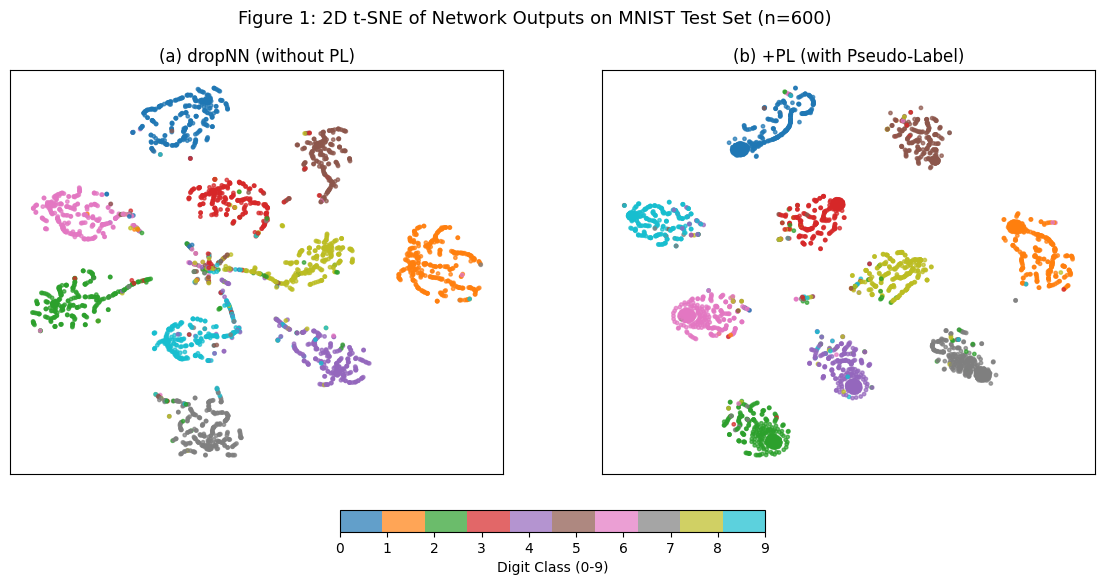

In [7]:
# shortcut: subsample 3000 test points for fast Colab t-SNE, upgrade to 10000 if desired
sub_g = torch.Generator().manual_seed(42)
sub_idx = torch.randperm(len(X_test), generator=sub_g)[:3000]
X_sub = X_test[sub_idx.to(device)]
y_sub = y_test[sub_idx.to(device)].cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_models = [("(a) dropNN (without PL)", models_600["dropNN"]), ("(b) +PL (with Pseudo-Label)", models_600["+PL"])]

for ax, (title, m) in zip(axes, plot_models):
    m.eval()
    with torch.no_grad():
        probs_sub = m.predict_proba(X_sub).cpu().numpy()
    tsne_2d = TSNE(n_components=2, random_state=42, init="pca", learning_rate="auto").fit_transform(probs_sub)
    scatter = ax.scatter(tsne_2d[:, 0], tsne_2d[:, 1], c=y_sub, cmap="tab10", s=6, alpha=0.7)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])

fig.colorbar(scatter, ax=axes.ravel().tolist(), orientation="horizontal", fraction=0.046, pad=0.08, label="Digit Class (0-9)")
plt.suptitle("Figure 1: 2D t-SNE of Network Outputs on MNIST Test Set (n=600)", fontsize=13)
plt.show()


## 6. Figure 2 Reproduction: First Hidden Layer Filter Visualization (n_labeled = 600)


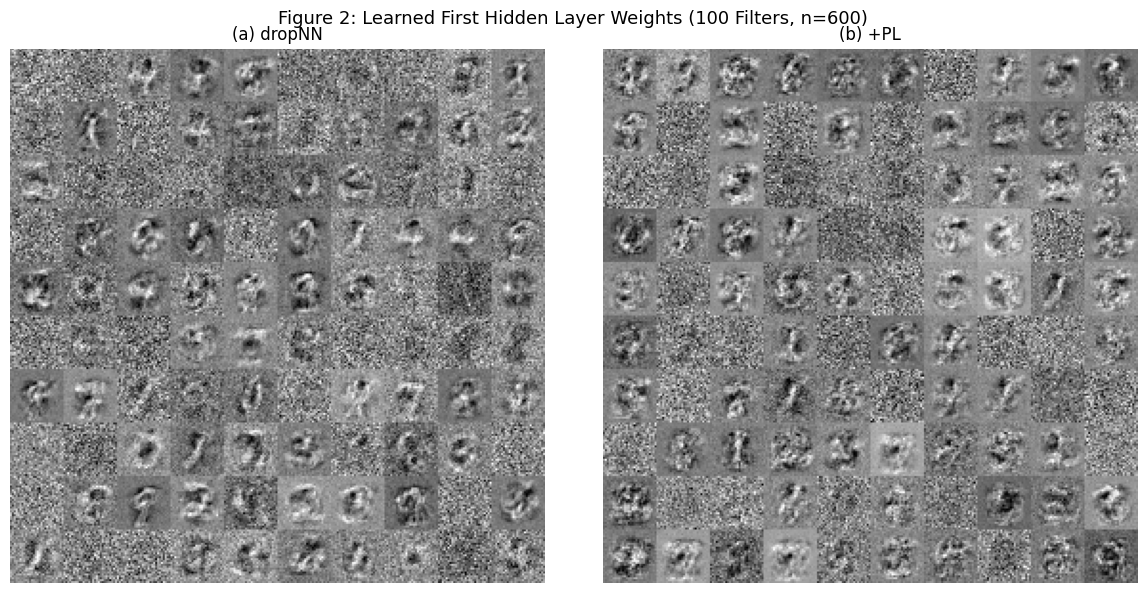

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
filter_models = [("(a) dropNN", models_600["dropNN"]), ("(b) +PL", models_600["+PL"])]

for ax, (title, m) in zip(axes, filter_models):
    weights = m.fc1.weight.detach().cpu()[:100].view(100, 28, 28)
    w_min = weights.amin(dim=(1, 2), keepdim=True)
    w_max = weights.amax(dim=(1, 2), keepdim=True)
    weights = (weights - w_min) / (w_max - w_min + 1e-8)
    grid = weights.view(10, 10, 28, 28).permute(0, 2, 1, 3).reshape(10 * 28, 10 * 28)
    ax.imshow(grid, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.suptitle("Figure 2: Learned First Hidden Layer Weights (100 Filters, n=600)", fontsize=13)
plt.tight_layout()
plt.show()
